### Syed Sirajuddin
### AAI 530: Data Analytics and Internet of Things  
### 2/16/2026

# **Assignment 6.1: Pre-Trained Generative Model Report**


In [ ]:
#!python -m pip install pygame
#!python -m pip install pillow

   ---------------------------------------- 0.0/7.0 MB ? eta -:--:--
   ----------------------------- ---------- 5.2/7.0 MB 30.7 MB/s eta 0:00:01
   ---------------------------------------- 7.0/7.0 MB 31.9 MB/s  0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ultralytics 8.3.227 requires matplotlib>=3.3.0, which is not installed.
ultralytics 8.3.227 requires numpy>=1.23.0, which is not installed.
ultralytics 8.3.227 requires pyyaml>=5.3.1, which is not installed.
ultralytics 8.3.227 requires scipy>=1.4.1, which is not installed.
ultralytics 8.3.227 requires torch!=2.4.0,>=1.8.0; sys_platform == "win32", which is not installed.
ultralytics 8.3.227 requires torch>=1.8.0, which is not installed.
ultralytics 8.3.227 requires torchvision>=0.9.0, which is not installed.


## **Initial Doom Game**

In my initial attempt to use LLM to produce a game, I asked ChatGPT to create a Doom like game to program. The following image shows the initial prompt and the code below is what it told me to create:

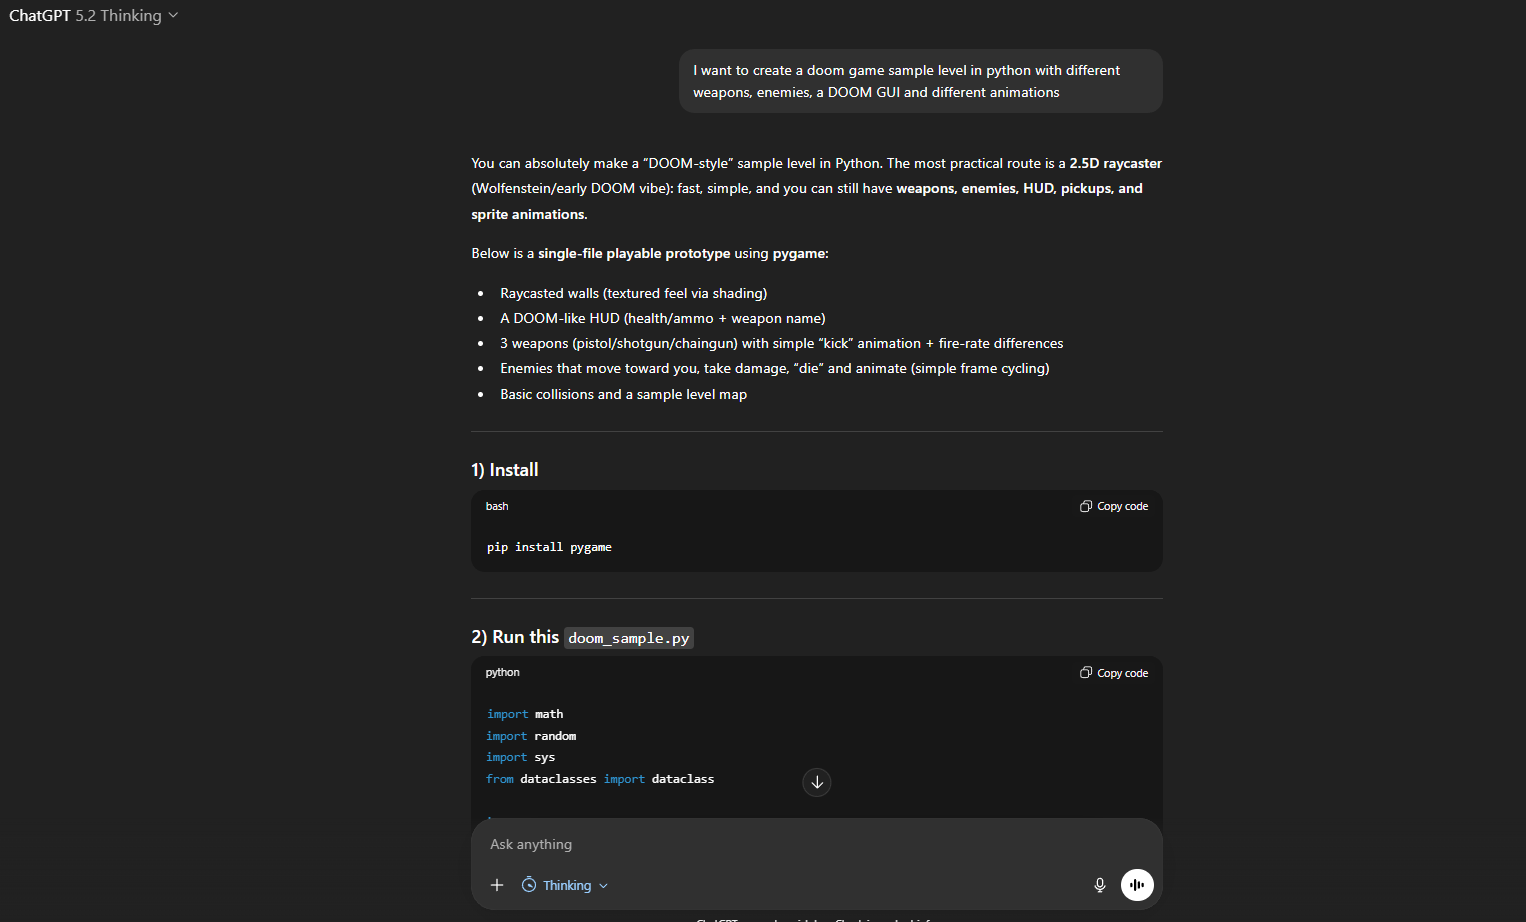

Below is the image of the game that runs:

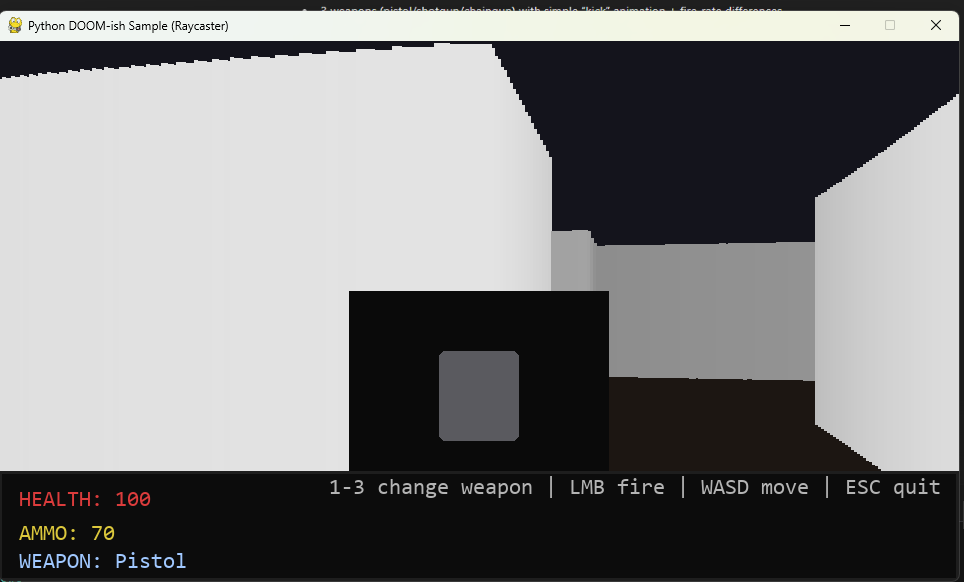

One thing that I had to fix was the movement in the game (W,A,S,D) was not working properly. Using my own python knowledge as well as ChatGPT, I was able to solve it.

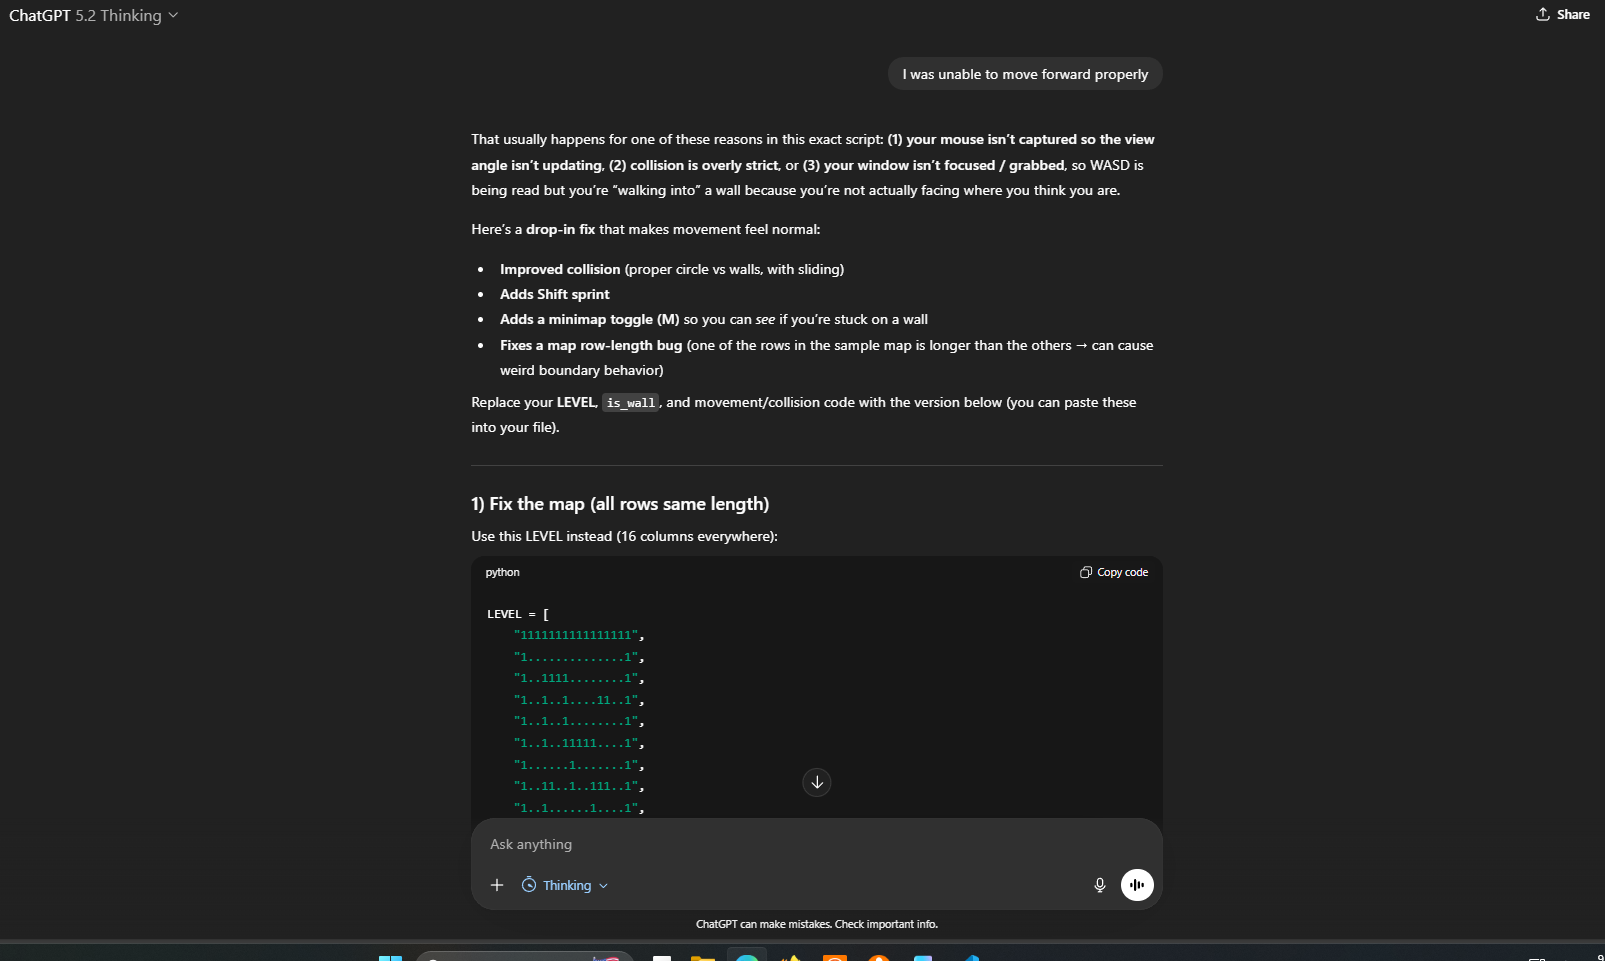

In [10]:
import math
import random
import sys
from dataclasses import dataclass

import pygame

# ----------------------------
# Config
# ----------------------------
W, H = 960, 540
HALF_W, HALF_H = W // 2, H // 2
FPS = 60

FOV = math.radians(70)
HALF_FOV = FOV / 2
NUM_RAYS = 320
MAX_DEPTH = 20
DELTA_ANGLE = FOV / NUM_RAYS
DIST_TO_PLANE = (W / 2) / math.tan(HALF_FOV)
RAY_STEP = 0.02

TILE = 1.0  # map tiles are 1x1 units

MOUSE_SENS = 0.0025
MOVE_SPEED = 2.8  # units/sec
ROT_SPEED = 2.2   # rad/sec

# ----------------------------
# Sample Level Map (1 = wall)
# ----------------------------
LEVEL = [
    "1111111111111111",
    "1..............1",
    "1..1111........1",
    "1..1..1....11..1",
    "1..1..1........1",
    "1..1..11111....1",
    "1......1.......1",
    "1..11..1..111..1",
    "1..1......1....1",
    "1..1..11111....1",
    "1..............1",
    "1111111111111111",
]
MAP_H = len(LEVEL)
MAP_W = len(LEVEL[0])

def is_wall(x, y):
    ix, iy = int(x), int(y)
    if ix < 0 or iy < 0 or ix >= MAP_W or iy >= MAP_H:
        return True
    return LEVEL[iy][ix] == "1"

def clamp(v, a, b):
    return max(a, min(b, v))

# ----------------------------
# Weapons
# ----------------------------
@dataclass
class Weapon:
    name: str
    damage: int
    fire_delay: float     # seconds between shots
    spread: float         # radians
    pellets: int          # number of hitscan pellets
    ammo_cost: int
    kick: float           # visual kick amplitude

WEAPONS = [
    Weapon("Pistol",   damage=18, fire_delay=0.25, spread=math.radians(1.0), pellets=1,  ammo_cost=1, kick=10),
    Weapon("Shotgun",  damage=10, fire_delay=0.90, spread=math.radians(7.0), pellets=7,  ammo_cost=1, kick=28),
    Weapon("Chaingun", damage=11, fire_delay=0.10, spread=math.radians(2.5), pellets=1,  ammo_cost=1, kick=14),
]

# ----------------------------
# Enemies (sprites)
# ----------------------------
@dataclass
class Enemy:
    x: float
    y: float
    hp: int = 60
    alive: bool = True
    anim_t: float = 0.0
    frame: int = 0
    death_t: float = 0.0

    def dist_to(self, px, py):
        return math.hypot(self.x - px, self.y - py)

# Spawn a few enemies
ENEMIES = [
    Enemy(8.5, 2.5, 60),
    Enemy(12.5, 9.5, 80),
    Enemy(5.5, 9.0, 60),
    Enemy(10.0, 6.5, 60),
]

# ----------------------------
# Raycasting
# ----------------------------
def cast_rays(px, py, angle):
    rays = []
    start_angle = angle - HALF_FOV
    for r in range(NUM_RAYS):
        ray_angle = start_angle + r * DELTA_ANGLE
        sin_a = math.sin(ray_angle)
        cos_a = math.cos(ray_angle)

        depth = 0.0
        while depth < MAX_DEPTH:
            depth += RAY_STEP
            x = px + cos_a * depth
            y = py + sin_a * depth
            if is_wall(x, y):
                # simple perpendicular correction (fish-eye)
                depth_corr = depth * math.cos(angle - ray_angle)
                rays.append((depth_corr, ray_angle))
                break
        else:
            rays.append((MAX_DEPTH, ray_angle))
    return rays

def wall_shade(depth):
    # closer -> brighter
    # clamp to keep walls visible
    shade = 255 - int(depth * 22)
    return clamp(shade, 20, 255)

# ----------------------------
# Hitscan shooting
# ----------------------------
def shoot_hitscan(px, py, angle, weapon: Weapon):
    global ammo
    if ammo < weapon.ammo_cost:
        return None

    ammo -= weapon.ammo_cost

    hits = []
    for _ in range(weapon.pellets):
        a = angle + random.uniform(-weapon.spread, weapon.spread)
        sin_a = math.sin(a)
        cos_a = math.cos(a)

        depth = 0.0
        hit_enemy = None
        hit_dist = MAX_DEPTH

        while depth < MAX_DEPTH:
            depth += RAY_STEP
            x = px + cos_a * depth
            y = py + sin_a * depth
            if is_wall(x, y):
                hit_dist = depth
                break

            # enemy hit test (circle)
            for e in ENEMIES:
                if not e.alive:
                    continue
                if math.hypot(e.x - x, e.y - y) < 0.25:
                    hit_enemy = e
                    hit_dist = depth
                    depth = MAX_DEPTH
                    break

        if hit_enemy is not None:
            hits.append(hit_enemy)

    # apply damage to closest-ish enemies hit (each pellet can hit)
    for e in hits:
        e.hp -= weapon.damage
        if e.hp <= 0 and e.alive:
            e.alive = False
            e.death_t = 0.0

    return hits

# ----------------------------
# Rendering helpers
# ----------------------------
def draw_minimap(screen, px, py):
    scale = 10
    ox, oy = 10, 10
    for y in range(MAP_H):
        for x in range(MAP_W):
            c = (60,60,60) if LEVEL[y][x] == "1" else (20,20,20)
            pygame.draw.rect(screen, c, (ox + x*scale, oy + y*scale, scale-1, scale-1))
    pygame.draw.circle(screen, (255, 200, 60), (int(ox + px*scale), int(oy + py*scale)), 3)

def draw_floor_and_ceiling(screen):
    # ceiling
    screen.fill((20, 20, 28))
    # floor
    pygame.draw.rect(screen, (28, 22, 18), (0, HALF_H, W, HALF_H))

def draw_walls(screen, rays):
    ray_w = W / NUM_RAYS
    for i, (depth, _a) in enumerate(rays):
        if depth <= 0.001:
            depth = 0.001
        proj_h = int(DIST_TO_PLANE / depth)
        shade = wall_shade(depth)
        color = (shade, shade, shade)
        x = int(i * ray_w)
        y = HALF_H - proj_h // 2
        pygame.draw.rect(screen, color, (x, y, int(ray_w + 1), proj_h))

def angle_diff(a, b):
    d = (a - b + math.pi) % (2 * math.pi) - math.pi
    return d

def is_visible(px, py, view_a, ex, ey):
    # quick visibility: within FOV and not behind a wall (coarse ray step)
    dx = ex - px
    dy = ey - py
    ang = math.atan2(dy, dx)
    if abs(angle_diff(ang, view_a)) > HALF_FOV:
        return False

    dist = math.hypot(dx, dy)
    steps = int(dist / 0.05)
    if steps <= 0:
        return True
    for i in range(steps):
        t = (i + 1) / steps
        x = px + dx * t
        y = py + dy * t
        if is_wall(x, y):
            return False
    return True

def draw_enemies(screen, px, py, angle):
    # painter's algorithm: draw farthest first
    visible = []
    for e in ENEMIES:
        d = e.dist_to(px, py)
        if d < MAX_DEPTH and is_visible(px, py, angle, e.x, e.y):
            visible.append((d, e))
    visible.sort(reverse=True, key=lambda t: t[0])

    for dist, e in visible:
        # project sprite
        dx = e.x - px
        dy = e.y - py
        sprite_a = math.atan2(dy, dx)
        rel_a = angle_diff(sprite_a, angle)

        # screen x
        x_on_plane = math.tan(rel_a) * DIST_TO_PLANE
        sx = int(HALF_W + x_on_plane)

        # size
        if dist < 0.001:
            dist = 0.001
        size = int(DIST_TO_PLANE / dist * 0.9)

        # animation frame
        if e.alive:
            # 4-frame walk loop
            col = [(180, 40, 40), (200, 60, 60), (180, 40, 40), (160, 30, 30)][e.frame]
        else:
            # 3-frame death fade
            col = [(80, 20, 20), (55, 15, 15), (30, 10, 10)][min(e.frame, 2)]

        rect = pygame.Rect(sx - size // 2, HALF_H - size // 2, size, size)
        pygame.draw.ellipse(screen, col, rect)

        # small "eyes" for alive enemies
        if e.alive and size > 20:
            eye_y = rect.y + rect.h * 0.35
            pygame.draw.circle(screen, (240, 240, 240), (rect.centerx - rect.w // 6, int(eye_y)), max(2, size // 18))
            pygame.draw.circle(screen, (240, 240, 240), (rect.centerx + rect.w // 6, int(eye_y)), max(2, size // 18))

def draw_hud(screen, font, weapon: Weapon):
    # DOOM-ish HUD bar
    hud_h = 110
    pygame.draw.rect(screen, (12, 12, 12), (0, H - hud_h, W, hud_h))
    pygame.draw.rect(screen, (30, 30, 30), (0, H - hud_h, W, hud_h), 3)

    # Health / Ammo
    txt1 = font.render(f"HEALTH: {health}", True, (220, 60, 60))
    txt2 = font.render(f"AMMO: {ammo}", True, (220, 200, 60))
    txt3 = font.render(f"WEAPON: {weapon.name}", True, (160, 200, 255))
    screen.blit(txt1, (20, H - hud_h + 18))
    screen.blit(txt2, (20, H - hud_h + 52))
    screen.blit(txt3, (20, H - hud_h + 80))

    # Crosshair
    cx, cy = HALF_W, HALF_H
    pygame.draw.line(screen, (240, 240, 240), (cx - 8, cy), (cx + 8, cy), 2)
    pygame.draw.line(screen, (240, 240, 240), (cx, cy - 8), (cx, cy + 8), 2)

def draw_weapon(screen, weapon: Weapon, fire_kick, font):
    # simple weapon "sprite" as a rect + animated kick
    base_w, base_h = 260, 180
    x = HALF_W - base_w // 2
    y = H - 110 - base_h + int(fire_kick)

    # different weapon silhouettes
    if weapon.name == "Pistol":
        col = (90, 90, 95)
        shape = pygame.Rect(x + 90, y + 60, 80, 90)
    elif weapon.name == "Shotgun":
        col = (100, 80, 60)
        shape = pygame.Rect(x + 40, y + 65, 180, 80)
    else:  # Chaingun
        col = (70, 75, 85)
        shape = pygame.Rect(x + 55, y + 55, 150, 100)

    pygame.draw.rect(screen, (10, 10, 10), (x, y, base_w, base_h))
    pygame.draw.rect(screen, col, shape, border_radius=6)

    # muzzle flash (quick)
    if fire_kick < -2:
        mx = shape.right + 10
        my = shape.y + shape.h // 2
        pygame.draw.circle(screen, (255, 240, 120), (mx, my), 10)
        pygame.draw.circle(screen, (255, 200, 80), (mx, my), 6)

    # tip text
    tip = font.render("1-3 change weapon | LMB fire | WASD move | ESC quit", True, (180, 180, 180))
    screen.blit(tip, (W - tip.get_width() - 18, H - 105))

# ----------------------------
# Game State
# ----------------------------
pygame.init()
show_map = True
screen = pygame.display.set_mode((W, H))
pygame.event.set_grab(True)
pygame.mouse.set_visible(False)
pygame.mouse.get_rel()  # flush initial motion

pygame.display.set_caption("Python DOOM-ish Sample (Raycaster)")
clock = pygame.time.Clock()
font = pygame.font.SysFont("consolas", 22)

pygame.mouse.set_visible(False)
pygame.event.set_grab(True)

px, py = 2.5, 2.5
angle = 0.0

health = 100
ammo = 70

weapon_idx = 0
current_weapon = WEAPONS[weapon_idx]
time_since_shot = 999.0
fire_kick = 0.0

PLAYER_RADIUS = 0.18

def collides(x, y):
    # check four sample points around the player circle
    r = PLAYER_RADIUS
    return (
        is_wall(x + r, y) or is_wall(x - r, y) or
        is_wall(x, y + r) or is_wall(x, y - r) or
        is_wall(x + r, y + r) or is_wall(x - r, y - r) or
        is_wall(x + r, y - r) or is_wall(x - r, y + r)
    )

def try_move(px, py, nx, ny):
    # slide on X then Y
    if not collides(nx, py):
        px = nx
    if not collides(px, ny):
        py = ny
    return px, py

# ----------------------------
# Main Loop
# ----------------------------
running = True
while running:
    dt = clock.tick(FPS) / 1000.0
    time_since_shot += dt

    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            running = False

        if event.type == pygame.KEYDOWN:
            if event.key == pygame.K_ESCAPE:
                running = False
            if event.key == pygame.K_1:
                weapon_idx = 0
            if event.key == pygame.K_2:
                weapon_idx = 1
            if event.key == pygame.K_3:
                weapon_idx = 2
            if event.key == pygame.K_m:
                show_map = not show_map
            current_weapon = WEAPONS[weapon_idx]
            firing = False
            fire_t = 0.0

        if event.type == pygame.MOUSEMOTION:
            mx, _my = event.rel
            angle += mx * MOUSE_SENS
            
        if event.type == pygame.ACTIVEEVENT:
            pygame.event.set_grab(True)
    # Movement
    keys = pygame.key.get_pressed()
    speed = MOVE_SPEED * (1.6 if keys[pygame.K_LSHIFT] or keys[pygame.K_RSHIFT] else 1.0)
    move = speed * dt
    dx = math.cos(angle) * move
    dy = math.sin(angle) * move
    strafe_x = math.cos(angle + math.pi / 2) * move
    strafe_y = math.sin(angle + math.pi / 2) * move

    nx, ny = px, py
    if keys[pygame.K_w]:
        nx += dx; ny += dy
    if keys[pygame.K_s]:
        nx -= dx; ny -= dy
    if keys[pygame.K_a]:
        nx -= strafe_x; ny -= strafe_y
    if keys[pygame.K_d]:
        nx += strafe_x; ny += strafe_y

    # Arrow keys rotation option
    if keys[pygame.K_LEFT]:
        angle -= ROT_SPEED * dt
    if keys[pygame.K_RIGHT]:
        angle += ROT_SPEED * dt

    # Apply collision
    px, py = try_move(px, py, nx, ny)

    # Shooting
    mouse_buttons = pygame.mouse.get_pressed()
    if mouse_buttons[0] and time_since_shot >= current_weapon.fire_delay:
        shoot_hitscan(px, py, angle, current_weapon)
        time_since_shot = 0.0
        fire_kick = -current_weapon.kick

    # Ease weapon kick back down
    fire_kick = min(0.0, fire_kick + 120 * dt)

    # Enemy AI / animation
    for e in ENEMIES:
        if e.alive:
            # animate walk
            e.anim_t += dt
            if e.anim_t >= 0.12:
                e.anim_t = 0.0
                e.frame = (e.frame + 1) % 4

            # simple chase if visible-ish
            if e.dist_to(px, py) > 0.7:
                vx = px - e.x
                vy = py - e.y
                d = math.hypot(vx, vy) + 1e-6
                vx /= d
                vy /= d

                step = 1.25 * dt
                nx = e.x + vx * step
                ny = e.y + vy * step
                if not is_wall(nx, ny):
                    e.x, e.y = nx, ny

            # damage player if too close
            if e.dist_to(px, py) < 0.65:
                health -= int(22 * dt)  # DPS-ish
                health = max(0, health)

        else:
            # death animation
            e.death_t += dt
            if e.death_t >= 0.18:
                e.death_t = 0.0
                e.frame += 1

    # Render
    rays = cast_rays(px, py, angle)

    draw_floor_and_ceiling(screen)
    draw_walls(screen, rays)
    draw_enemies(screen, px, py, angle)
    draw_hud(screen, font, current_weapon)
    draw_weapon(screen, current_weapon, fire_kick, font)

    # Game over overlay
    if health <= 0:
        overlay = pygame.Surface((W, H), pygame.SRCALPHA)
        overlay.fill((120, 0, 0, 140))
        screen.blit(overlay, (0, 0))
        msg = font.render("YOU DIED - press ESC", True, (255, 220, 220))
        screen.blit(msg, (HALF_W - msg.get_width() // 2, HALF_H - 20))

    pygame.display.flip()

pygame.quit()
sys.exit()


SystemExit: 

## **Doom Plus**

AFter I created the Doom Game, I wanted to have some additional Doom-like gameplay enemies, like enemies, pickup and sprites. 

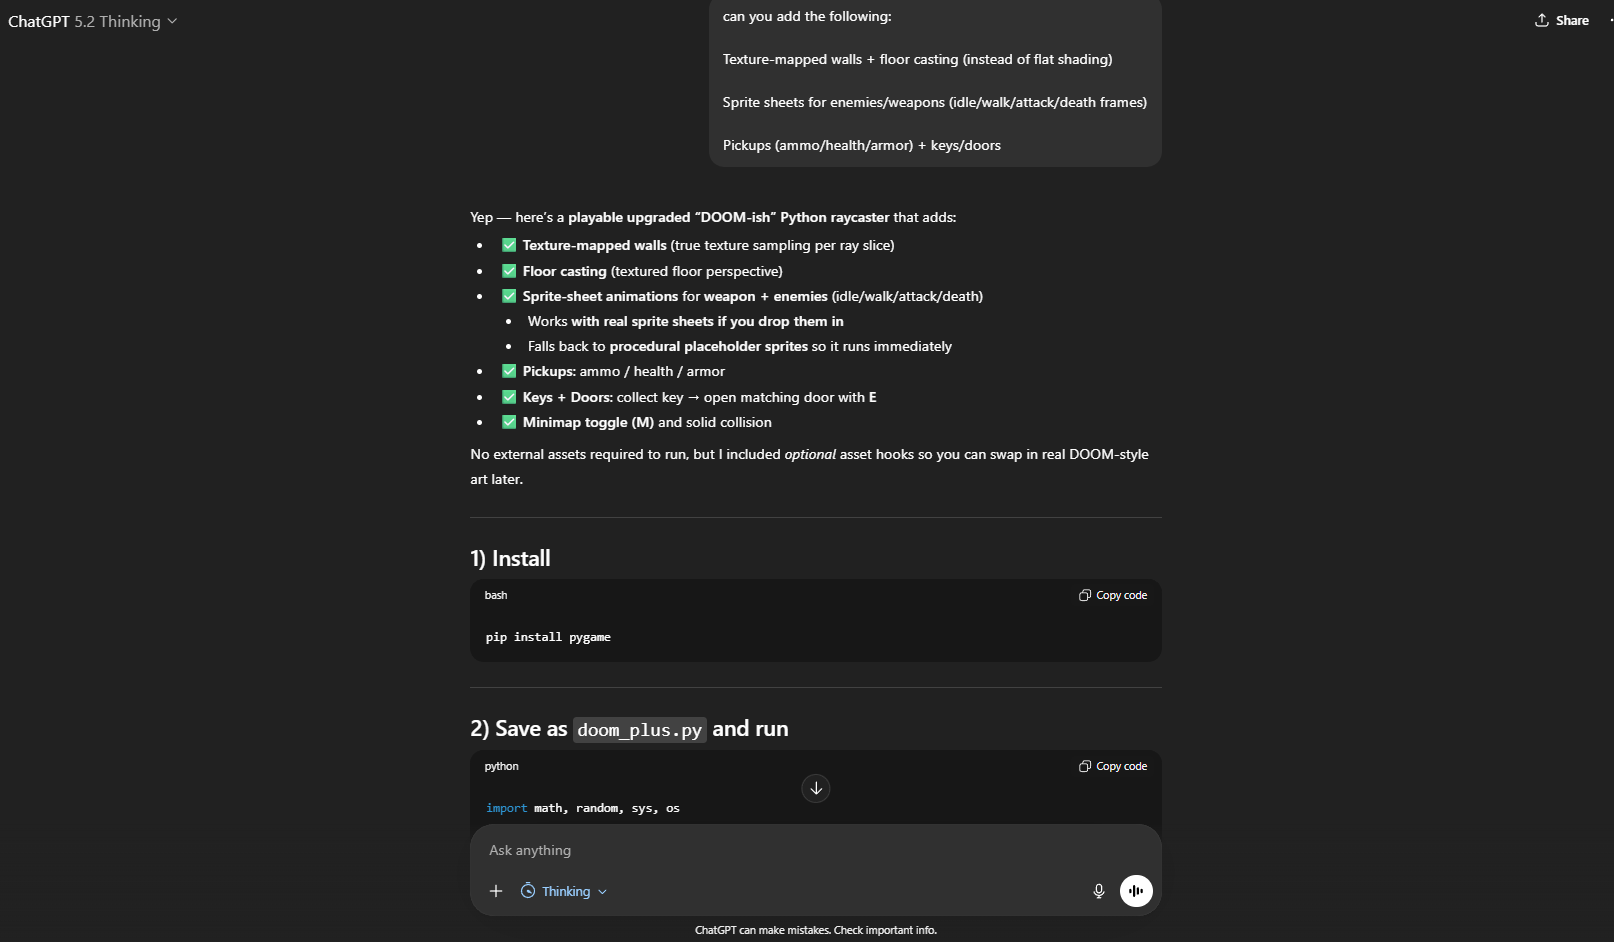

I also used ChatGPT to create the sprites:

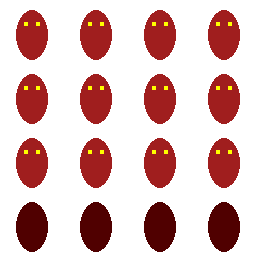
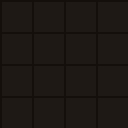
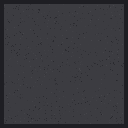
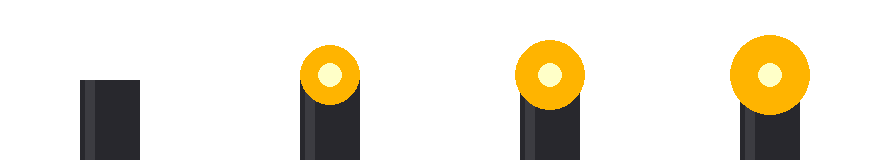


The Final result was a doom Game you can run below:

In [12]:
import math, random, sys, os
from dataclasses import dataclass
import pygame

# ----------------------------
# SETTINGS
# ----------------------------
W, H = 960, 540
HALF_W, HALF_H = W // 2, H // 2
FPS = 60

FOV = math.radians(70)
HALF_FOV = FOV / 2
NUM_RAYS = 320
DELTA_ANGLE = FOV / NUM_RAYS
DIST_TO_PLANE = (W / 2) / math.tan(HALF_FOV)
MAX_DEPTH = 20.0
RAY_STEP = 0.02

MOVE_SPEED = 2.9
ROT_SPEED = 2.2
MOUSE_SENS = 0.0026

# World tiles are 1x1
TILE = 1.0
PLAYER_RADIUS = 0.18

# ----------------------------
# MAP LEGEND
# ----------------------------
# 1 = wall
# . = empty
# A = ammo pickup
# H = health pickup
# R = armor pickup
# k = key pickup (yellow key)
# D = locked door (needs yellow key)
LEVEL = [
    "1111111111111111",
    "1....A..........1",
    "1..1111.....k...1",
    "1..1..1....11...1",
    "1..1..1.........1",
    "1..1..11111..D..1",
    "1......1.....R..1",
    "1..11..1..111...1",
    "1..1......1..H..1",
    "1..1..11111.....1",
    "1...............1",
    "1111111111111111",
]
MAP_H = len(LEVEL)
MAP_W = len(LEVEL[0])

def clamp(v, a, b): return max(a, min(b, v))

def in_bounds(ix, iy):
    return 0 <= ix < MAP_W and 0 <= iy < MAP_H

def tile_at(x, y):
    ix, iy = int(x), int(y)
    if not in_bounds(ix, iy):
        return "1"
    return LEVEL[iy][ix]

def is_wall(x, y):
    t = tile_at(x, y)
    return t == "1" or t == "D"

# ----------------------------
# ASSETS (optional)
# ----------------------------
# If you put files in ./assets/, these will load:
# - assets/wall.png (64x64)
# - assets/floor.png (64x64)
# - assets/weapon.png (sprite sheet: columns x rows)
# - assets/enemy.png  (sprite sheet: columns x rows)
#
# If missing, we generate procedural textures/sprites.

BASE_DIR = os.path.dirname(__file__) if "__file__" in globals() else os.getcwd()
ASSET_DIR = os.path.join(BASE_DIR, "assets")
print("ASSET_DIR =", ASSET_DIR)

def load_image(path):
    try:
        img = pygame.image.load(path)
        # Preserve alpha (transparent background) if present
        return img.convert_alpha()
    except Exception:
        return None
    
def load_sprite_sheet(path, colorkey=None):
    try:
        img = pygame.image.load(path).convert_alpha()
        if colorkey is not None:
            img.set_colorkey(colorkey)
        return img
    except Exception:
        return None
    
def make_checker_texture(size=64, a=(120,120,120), b=(70,70,70), block=8):
    surf = pygame.Surface((size, size))
    for y in range(0, size, block):
        for x in range(0, size, block):
            c = a if ((x//block + y//block) % 2 == 0) else b
            pygame.draw.rect(surf, c, (x, y, block, block))
    return surf.convert()

def make_floor_texture(size=64):
    surf = pygame.Surface((size, size))
    surf.fill((40, 28, 18))
    # “grime” stripes
    for i in range(0, size, 4):
        pygame.draw.line(surf, (45+i%15, 32, 20), (0, i), (size, i))
    return surf.convert()

def make_placeholder_sprite_sheet(frame_w, frame_h, cols, rows, base_color):
    sheet = pygame.Surface((frame_w*cols, frame_h*rows), pygame.SRCALPHA)
    for r in range(rows):
        for c in range(cols):
            x, y = c*frame_w, r*frame_h
            # slight variation per frame
            col = (clamp(base_color[0]+(c*12 - r*8), 0, 255),
                   clamp(base_color[1]+(r*10 - c*6), 0, 255),
                   clamp(base_color[2]+(c*5), 0, 255))
            pygame.draw.rect(sheet, col, (x+4, y+4, frame_w-8, frame_h-8), border_radius=8)
            pygame.draw.circle(sheet, (240,240,240), (x+frame_w//3, y+frame_h//3), 4)
            pygame.draw.circle(sheet, (240,240,240), (x+2*frame_w//3, y+frame_h//3), 4)
    return sheet

pygame.init()
screen = pygame.display.set_mode((W, H))
pygame.display.set_caption("Python DOOM-ish ++")
clock = pygame.time.Clock()
# Load textures
wall_img = load_image(os.path.join(ASSET_DIR, "wall.png"))
floor_img = load_image(os.path.join(ASSET_DIR, "floor.png"))
if wall_img is None: wall_img = make_checker_texture(64, (150,150,160), (70,70,80), 8)
else: wall_img = wall_img.convert()
if floor_img is None: floor_img = make_floor_texture(64)
else: floor_img = floor_img.convert()

TEX_SIZE = 64
wall_tex = pygame.transform.smoothscale(wall_img, (TEX_SIZE, TEX_SIZE))
floor_tex = pygame.transform.smoothscale(floor_img, (TEX_SIZE, TEX_SIZE))

# ----------------------------
# ANIMATION SYSTEM
# ----------------------------
class AnimSet:
    """
    A sprite sheet with named animations using frame index lists.
    """
    def __init__(self, sheet, frame_w, frame_h, cols, rows, animations, fps=10):
        self.sheet = sheet
        self.frame_w = frame_w
        self.frame_h = frame_h
        self.cols = cols
        self.rows = rows
        self.frames = []
        for r in range(rows):
            for c in range(cols):
                rect = pygame.Rect(c*frame_w, r*frame_h, frame_w, frame_h)
                self.frames.append(sheet.subsurface(rect).copy())
        self.animations = animations
        self.fps = fps

    def get_frame(self, anim_name, t):
        seq = self.animations[anim_name]
        idx = int(t * self.fps) % len(seq)
        return self.frames[seq[idx]]

# Weapon spritesheet: 4x1 (idle, fire1, fire2, fire3)
weapon_sheet = load_sprite_sheet(os.path.join(ASSET_DIR, "weapon.png"))   # NO colorkey
if weapon_sheet is None:
    weapon_sheet = make_placeholder_sprite_sheet(220, 160, cols=4, rows=1, base_color=(90,90,95))
weapon_anims = {
    "idle": [0],
    "fire": [1,2,3,2],
}
weapon_anim = AnimSet(weapon_sheet, 220, 160, cols=4, rows=1, animations=weapon_anims, fps=14)
print("weapon_sheet =", weapon_sheet)
if weapon_sheet:
    print("weapon_sheet size =", weapon_sheet.get_size(), "alpha?", bool(weapon_sheet.get_flags() & pygame.SRCALPHA))
if weapon_sheet:
    screen.blit(weapon_sheet, (10, 140))  # raw sprite sheet preview

# Enemy spritesheet: 4x4 arranged by rows:
# row 0 = idle (4 frames)
# row 1 = walk (4 frames)
# row 2 = attack (4 frames)
# row 3 = death (4 frames)
enemy_sheet  = load_sprite_sheet(os.path.join(ASSET_DIR, "enemy.png"))    # NO colorkey
if enemy_sheet is None:
    enemy_sheet = make_placeholder_sprite_sheet(64, 64, cols=4, rows=4, base_color=(170,50,50))
enemy_anims = {
    "idle":   [0,1,2,3],
    "walk":   [4,5,6,7],
    "attack": [8,9,10,11],
    "death":  [12,13,14,15],
}
enemy_anim = AnimSet(enemy_sheet, 64, 64, cols=4, rows=4, animations=enemy_anims, fps=10)

# ----------------------------
# GAME OBJECTS
# ----------------------------
@dataclass
class Pickup:
    x: float
    y: float
    kind: str  # 'A','H','R','k'
    alive: bool = True

@dataclass
class Enemy:
    x: float
    y: float
    hp: int = 70
    state: str = "walk"    # idle/walk/attack/death
    alive: bool = True
    t: float = 0.0
    attack_cd: float = 0.0

    def dist_to(self, px, py):
        return math.hypot(self.x - px, self.y - py)

# ----------------------------
# WEAPONS
# ----------------------------
@dataclass
class Weapon:
    name: str
    damage: int
    fire_delay: float
    spread: float
    pellets: int
    ammo_cost: int

WEAPONS = [
    Weapon("Pistol",   18, 0.25, math.radians(1.2), 1, 1),
    Weapon("Shotgun",  10, 0.90, math.radians(7.0), 7, 1),
    Weapon("Chaingun", 11, 0.10, math.radians(2.6), 1, 1),
]

# ----------------------------
# Build pickups from map
# ----------------------------
pickups = []
mutable_level = [list(row) for row in LEVEL]
for y in range(MAP_H):
    for x in range(MAP_W):
        t = mutable_level[y][x]
        if t in ("A","H","R","k"):
            pickups.append(Pickup(x+0.5, y+0.5, t))
            mutable_level[y][x] = "."
LEVEL = ["".join(r) for r in mutable_level]

def set_tile(ix, iy, ch):
    global LEVEL
    rows = [list(r) for r in LEVEL]
    rows[iy][ix] = ch
    LEVEL = ["".join(r) for r in rows]

def tile_is_door(ix, iy):
    return in_bounds(ix, iy) and LEVEL[iy][ix] == "D"

# ----------------------------
# Raycasting: wall + floor casting
# ----------------------------
def cast_single_ray(px, py, ray_angle):
    sin_a = math.sin(ray_angle)
    cos_a = math.cos(ray_angle)

    depth = 0.0
    while depth < MAX_DEPTH:
        depth += RAY_STEP
        x = px + cos_a * depth
        y = py + sin_a * depth
        t = tile_at(x, y)
        if t == "1" or t == "D":
            # texture X coordinate from hit position
            hit_x = x - int(x)
            hit_y = y - int(y)
            # choose axis based on which fractional is "closer" to edge (rough)
            if abs(hit_x - 0.5) > abs(hit_y - 0.5):
                u = hit_y
            else:
                u = hit_x
            tex_x = int(u * (TEX_SIZE - 1))
            return depth, tex_x
    return MAX_DEPTH, 0

def cast_rays(px, py, view_angle):
    rays = []
    start_angle = view_angle - HALF_FOV
    for r in range(NUM_RAYS):
        ra = start_angle + r * DELTA_ANGLE
        d, tex_x = cast_single_ray(px, py, ra)
        # fish-eye correction
        d *= math.cos(view_angle - ra)
        rays.append((d, tex_x, ra))
    return rays

def floor_cast(screen, px, py, view_angle):
    """
    Textured floor casting from horizon to bottom.
    """
    # Ray directions for left and right edges of view
    left_a = view_angle - HALF_FOV
    right_a = view_angle + HALF_FOV
    sin_l, cos_l = math.sin(left_a), math.cos(left_a)
    sin_r, cos_r = math.sin(right_a), math.cos(right_a)

    # For each screen row below horizon
    for y in range(HALF_H, H):
        # distance from camera plane
        p = y - HALF_H
        if p == 0:
            continue
        row_dist = (DIST_TO_PLANE) / p  # classic raycaster floor formula

        # step across screen
        # world position at left & right for this row
        lx = px + cos_l * row_dist
        ly = py + sin_l * row_dist
        rx = px + cos_r * row_dist
        ry = py + sin_r * row_dist

        step_x = (rx - lx) / W
        step_y = (ry - ly) / W

        wx, wy = lx, ly
        for x in range(W):
            tx = int((wx % 1.0) * TEX_SIZE) & (TEX_SIZE - 1)
            ty = int((wy % 1.0) * TEX_SIZE) & (TEX_SIZE - 1)
            screen.set_at((x, y), floor_tex.get_at((tx, ty)))
            wx += step_x
            wy += step_y

# ----------------------------
# Rendering: walls with textures
# ----------------------------
def draw_textured_walls(screen, rays):
    ray_w = W / NUM_RAYS
    for i, (depth, tex_x, _ra) in enumerate(rays):
        if depth < 0.001:
            depth = 0.001
        proj_h = int(DIST_TO_PLANE / depth)

        # shade by distance
        shade = clamp(255 - int(depth * 18), 30, 255)

        x = int(i * ray_w)
        y = HALF_H - proj_h // 2

        # take one vertical column from texture, scale to projected height
        col = wall_tex.subsurface(pygame.Rect(tex_x, 0, 1, TEX_SIZE))
        col = pygame.transform.scale(col, (max(1, int(ray_w + 1)), proj_h))

        # apply shading via multiply
        shade_surf = pygame.Surface(col.get_size()).convert_alpha()
        shade_surf.fill((shade, shade, shade, 255))
        col.blit(shade_surf, (0,0), special_flags=pygame.BLEND_RGBA_MULT)

        screen.blit(col, (x, y))

# ----------------------------
# Visibility test for sprites
# ----------------------------
def angle_diff(a, b):
    d = (a - b + math.pi) % (2*math.pi) - math.pi
    return d

def line_of_sight(px, py, ex, ey):
    dx, dy = ex - px, ey - py
    dist = math.hypot(dx, dy)
    steps = int(dist / 0.05)
    if steps <= 0:
        return True
    for i in range(steps):
        t = (i+1)/steps
        x = px + dx*t
        y = py + dy*t
        if tile_at(x, y) in ("1","D"):
            return False
    return True

def draw_sprites(screen, px, py, view_angle, rays, enemies, pickups):
    # Build z-buffer from wall depths (one per ray)
    zbuf = [d for (d, _tx, _ra) in rays]

    items = []

    # enemies
    for e in enemies:
        d = e.dist_to(px, py)
        if d < MAX_DEPTH*0.95 and line_of_sight(px, py, e.x, e.y):
            items.append(("enemy", d, e))

    # pickups as sprites too
    for p in pickups:
        if not p.alive:
            continue
        d = math.hypot(p.x - px, p.y - py)
        if d < MAX_DEPTH*0.95 and line_of_sight(px, py, p.x, p.y):
            items.append(("pickup", d, p))

    # draw far to near
    items.sort(key=lambda t: t[1], reverse=True)

    for kind, dist, obj in items:
        dx = (obj.x - px)
        dy = (obj.y - py)
        ang = math.atan2(dy, dx)
        rel = angle_diff(ang, view_angle)

        if abs(rel) > HALF_FOV + 0.2:
            continue

        # screen x projection
        x_on_plane = math.tan(rel) * DIST_TO_PLANE
        sx = int(HALF_W + x_on_plane)

        if dist < 0.001:
            dist = 0.001

        if kind == "enemy":
            # choose animation frame
            frame = enemy_anim.get_frame(obj.state, obj.t)
            size = int(DIST_TO_PLANE / dist * 0.95)
            if size <= 2:
                continue
            sprite = pygame.transform.scale(frame, (size, size))
            sy = int(HALF_H - size//2)

        else:
            # pickups are small colored squares (replace with sprite later)
            size = int(DIST_TO_PLANE / dist * 0.35)
            size = max(8, min(40, size))
            sprite = pygame.Surface((size, size), pygame.SRCALPHA)
            if obj.kind == "A": c = (220, 200, 60)
            elif obj.kind == "H": c = (80, 220, 80)
            elif obj.kind == "R": c = (80, 160, 240)
            else: c = (240, 240, 120)  # key
            pygame.draw.rect(sprite, c, (0,0,size,size), border_radius=6)
            pygame.draw.rect(sprite, (0,0,0), (0,0,size,size), 2, border_radius=6)
            sy = int(HALF_H + 40 - size//2)

        # Occlusion test using z-buffer: convert sx to ray index
        ray_i = int((sx / W) * NUM_RAYS)
        if 0 <= ray_i < NUM_RAYS:
            # If wall is closer than sprite, don't draw
            if zbuf[ray_i] < dist:
                continue

        screen.blit(sprite, (sx - sprite.get_width()//2, sy))

# ----------------------------
# Collision / movement
# ----------------------------
def collides(x, y):
    r = PLAYER_RADIUS
    for ox in (-r, r):
        for oy in (-r, r):
            if is_wall(x + ox, y + oy):
                return True
    return False

def try_move(px, py, nx, ny):
    if not collides(nx, py):
        px = nx
    if not collides(px, ny):
        py = ny
    return px, py

# ----------------------------
# Shooting (hitscan)
# ----------------------------
def shoot(px, py, view_angle, weapon, enemies, ammo):
    if ammo < weapon.ammo_cost:
        return ammo

    ammo -= weapon.ammo_cost

    # each pellet casts a ray; first enemy hit before wall takes damage
    for _ in range(weapon.pellets):
        a = view_angle + random.uniform(-weapon.spread, weapon.spread)
        sin_a, cos_a = math.sin(a), math.cos(a)

        depth = 0.0
        hit_enemy = None

        while depth < MAX_DEPTH:
            depth += RAY_STEP
            x = px + cos_a * depth
            y = py + sin_a * depth
            if tile_at(x, y) in ("1","D"):
                break

            for e in enemies:
                if not e.alive:
                    continue
                if math.hypot(e.x - x, e.y - y) < 0.25:
                    hit_enemy = e
                    depth = MAX_DEPTH
                    break

        if hit_enemy is not None and hit_enemy.alive:
            hit_enemy.hp -= weapon.damage
            if hit_enemy.hp <= 0:
                hit_enemy.alive = False
                hit_enemy.state = "death"
                hit_enemy.t = 0.0

    return ammo

# ----------------------------
# HUD + Weapon render
# ----------------------------
def draw_hud(screen, font, health, armor, ammo, weapon, has_key):
    hud_h = 110
    pygame.draw.rect(screen, (12,12,12), (0, H - hud_h, W, hud_h))
    pygame.draw.rect(screen, (35,35,35), (0, H - hud_h, W, hud_h), 3)

    screen.blit(font.render(f"HEALTH: {health}", True, (220,60,60)), (18, H-hud_h+12))
    screen.blit(font.render(f"ARMOR : {armor}", True, (80,160,240)), (18, H-hud_h+40))
    screen.blit(font.render(f"AMMO  : {ammo}", True, (220,200,60)), (18, H-hud_h+68))
    screen.blit(font.render(f"WEAPON: {weapon.name}", True, (160,200,255)), (240, H-hud_h+68))

    key_txt = "YES" if has_key else "NO"
    screen.blit(font.render(f"YELLOW KEY: {key_txt}", True, (240,240,120)), (240, H-hud_h+12))

    # crosshair
    cx, cy = HALF_W, HALF_H
    pygame.draw.line(screen, (235,235,235), (cx-8, cy), (cx+8, cy), 2)
    pygame.draw.line(screen, (235,235,235), (cx, cy-8), (cx, cy+8), 2)

def draw_weapon(screen, firing, fire_t):
    # sprite from weapon sheet
    if firing:
        frame = weapon_anim.get_frame("fire", fire_t)
    else:
        frame = weapon_anim.get_frame("idle", 0.0)

    # scale + position
    scale = 1.3
    fw, fh = frame.get_width(), frame.get_height()
    img = pygame.transform.smoothscale(frame, (int(fw*scale), int(fh*scale)))

    x = HALF_W - img.get_width()//2
    y = H - 110 - img.get_height() + (0 if not firing else int(10*math.sin(fire_t*25)))
    screen.blit(img, (x, y))

# ----------------------------
# Minimap
# ----------------------------
def draw_minimap(screen, px, py, enemies, pickups):
    scale = 10
    ox, oy = 10, 10
    for y in range(MAP_H):
        for x in range(MAP_W):
            t = LEVEL[y][x]
            if t == "1": c = (80,80,80)
            elif t == "D": c = (180,150,60)
            else: c = (20,20,20)
            pygame.draw.rect(screen, c, (ox + x*scale, oy + y*scale, scale-1, scale-1))
    for p in pickups:
        if not p.alive: continue
        c = (220,200,60) if p.kind=="A" else (80,220,80) if p.kind=="H" else (80,160,240) if p.kind=="R" else (240,240,120)
        pygame.draw.circle(screen, c, (int(ox+p.x*scale), int(oy+p.y*scale)), 2)
    for e in enemies:
        if not e.alive: continue
        pygame.draw.circle(screen, (200,60,60), (int(ox+e.x*scale), int(oy+e.y*scale)), 2)
    pygame.draw.circle(screen, (255,255,255), (int(ox+px*scale), int(oy+py*scale)), 3)

# ----------------------------
# MAIN
# ----------------------------
pygame.init()
screen = pygame.display.set_mode((W,H))
pygame.display.set_caption("Python DOOM-ish ++ (textures, floor casting, sprites, pickups, doors)")
clock = pygame.time.Clock()
font = pygame.font.SysFont("consolas", 20)

pygame.event.set_grab(True)
pygame.mouse.set_visible(False)
pygame.mouse.get_rel()

# Player state
px, py = 2.5, 2.5
view_angle = 0.0

health = 100
armor = 0
ammo = 50
has_yellow_key = False

weapon_idx = 0
weapon = WEAPONS[weapon_idx]

# Enemy spawns
enemies = [
    Enemy(8.5, 2.5, 70),
    Enemy(12.5, 9.5, 90),
    Enemy(5.5, 9.0, 70),
    Enemy(10.0, 6.5, 70),
]

show_map = True
firing = False
fire_t = 0.0
time_since_shot = 999.0

running = True
while running:
    dt = clock.tick(FPS) / 1000.0
    time_since_shot += dt

    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            running = False

        if event.type == pygame.KEYDOWN:
            if event.key == pygame.K_ESCAPE:
                running = False

            if event.key == pygame.K_m:
                show_map = not show_map

            if event.key == pygame.K_1:
                weapon_idx = 0
            if event.key == pygame.K_2:
                weapon_idx = 1
            if event.key == pygame.K_3:
                weapon_idx = 2
            weapon = WEAPONS[weapon_idx]

            # Open door with E if you have key
            if event.key == pygame.K_e:
                fx = px + math.cos(view_angle) * 0.8
                fy = py + math.sin(view_angle) * 0.8
                ix, iy = int(fx), int(fy)
                if tile_is_door(ix, iy) and has_yellow_key:
                    set_tile(ix, iy, ".")  # remove door

        if event.type == pygame.MOUSEMOTION:
            mx, _ = event.rel
            view_angle += mx * MOUSE_SENS

    # movement
    keys = pygame.key.get_pressed()
    speed = MOVE_SPEED * (1.6 if keys[pygame.K_LSHIFT] or keys[pygame.K_RSHIFT] else 1.0)
    move = speed * dt

    dx = math.cos(view_angle) * move
    dy = math.sin(view_angle) * move
    sx = math.cos(view_angle + math.pi/2) * move
    sy = math.sin(view_angle + math.pi/2) * move

    nx, ny = px, py
    if keys[pygame.K_w]:
        nx += dx; ny += dy
    if keys[pygame.K_s]:
        nx -= dx; ny -= dy
    if keys[pygame.K_a]:
        nx -= sx; ny -= sy
    if keys[pygame.K_d]:
        nx += sx; ny += sy

    if keys[pygame.K_LEFT]:
        view_angle -= ROT_SPEED * dt
    if keys[pygame.K_RIGHT]:
        view_angle += ROT_SPEED * dt

    px, py = try_move(px, py, nx, ny)

    # pickups
    for p in pickups:
        if not p.alive:
            continue
        if math.hypot(p.x - px, p.y - py) < 0.45:
            if p.kind == "A":
                ammo += 12
            elif p.kind == "H":
                health = min(100, health + 25)
            elif p.kind == "R":
                armor = min(100, armor + 35)
            elif p.kind == "k":
                has_yellow_key = True
            p.alive = False

    # shooting
    mouse_buttons = pygame.mouse.get_pressed()
    if mouse_buttons[0] and time_since_shot >= weapon.fire_delay and ammo >= weapon.ammo_cost and health > 0:
        ammo = shoot(px, py, view_angle, weapon, enemies, ammo)
        time_since_shot = 0.0
        firing = True
        fire_t = 0.0

    if firing:
        fire_t += dt
        if fire_t > 0.18:  # weapon anim duration
            firing = False

    # enemy AI
    for e in enemies:
        e.t += dt
        if not e.alive:
            # run death anim for a bit, then stop at last frame
            if e.t > 0.6:
                e.t = 0.6
            continue

        e.attack_cd = max(0.0, e.attack_cd - dt)
        d = e.dist_to(px, py)

        can_see = line_of_sight(e.x, e.y, px, py)

        if d < 0.9 and can_see:
            e.state = "attack"
            # deal damage if cooldown allows
            if e.attack_cd <= 0.0 and health > 0:
                dmg = 10
                if armor > 0:
                    absorbed = min(armor, int(dmg * 0.6))
                    armor -= absorbed
                    dmg -= absorbed
                health = max(0, health - dmg)
                e.attack_cd = 0.75
        else:
            e.state = "walk"
            if can_see and d > 0.8:
                vx, vy = (px - e.x), (py - e.y)
                L = math.hypot(vx, vy) + 1e-6
                vx /= L; vy /= L
                step = 1.15 * dt
                tx, ty = e.x + vx*step, e.y + vy*step
                if not is_wall(tx, ty):
                    e.x, e.y = tx, ty

    # ----------------------------
    # RENDER
    # ----------------------------
    # sky (simple)
    screen.fill((18, 18, 28))

    # floor casting (textured)
    floor_cast(screen, px, py, view_angle)

    # rays
    rays = cast_rays(px, py, view_angle)

    # walls
    draw_textured_walls(screen, rays)

    # sprites (enemies + pickups)
    draw_sprites(screen, px, py, view_angle, rays, enemies, pickups)

    # hud + weapon
    draw_hud(screen, font, health, armor, ammo, weapon, has_yellow_key)
    draw_weapon(screen, firing, fire_t)

    if show_map:
        draw_minimap(screen, px, py, enemies, pickups)

    # help tip
    tip = font.render("WASD move | Mouse/←→ look | LMB fire | E open door | M minimap | 1-3 weapons", True, (190,190,190))
    screen.blit(tip, (W - tip.get_width() - 14, 12))

    # death overlay
    if health <= 0:
        ov = pygame.Surface((W, H), pygame.SRCALPHA)
        ov.fill((120, 0, 0, 120))
        screen.blit(ov, (0, 0))
        msg = font.render("YOU DIED - ESC to quit", True, (255, 230, 230))
        screen.blit(msg, (HALF_W - msg.get_width()//2, HALF_H - 16))

    pygame.display.flip()

pygame.quit()
sys.exit()


ASSET_DIR = d:\assignments\Assignments\AAi530\Assignment6\assets
weapon_sheet = <Surface(880x160x32 SW)>
weapon_sheet size = (880, 160) alpha? True


SystemExit: 

The result is shown in the screenshots below:

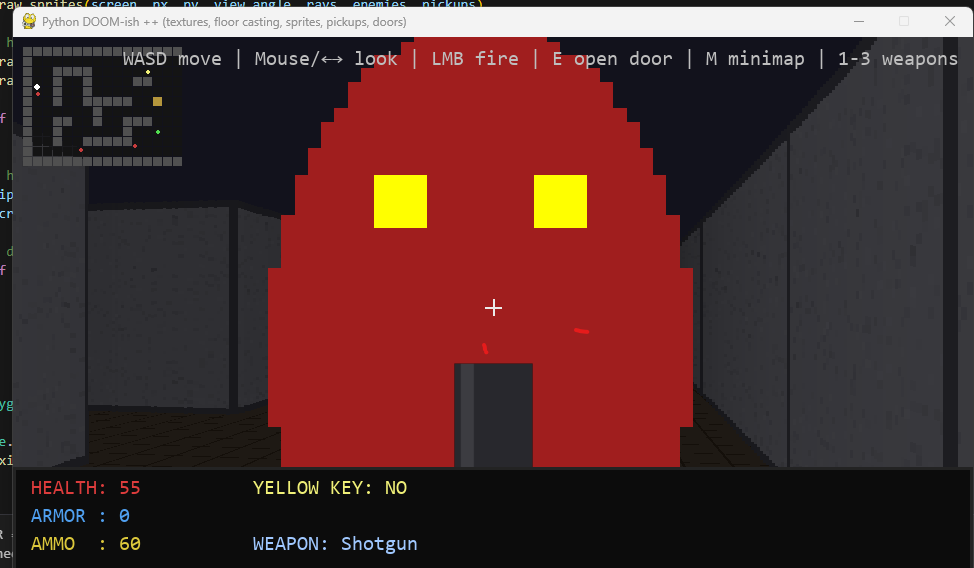
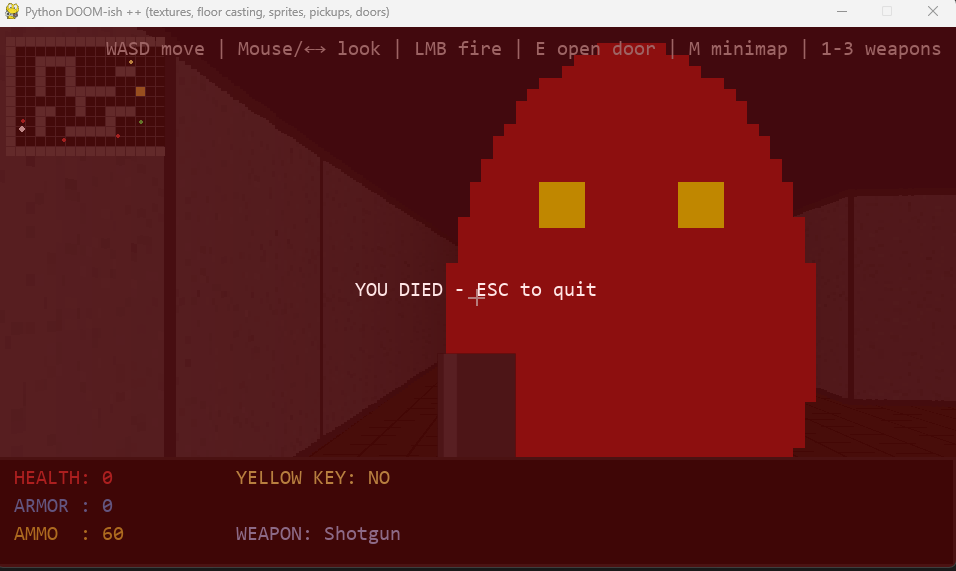

## Conclusion

Overall, my submission meets the Option 2 rubric because it shows a real back-and-forth workflow with the chatbot as a coding assistant, and the final code actually works for what I was trying to build. In the screenshot, I have multiple interactions where I asked for specific changes (textures, sprite transparency, switching between pistol/shotgun/minigun sprites), tested the results, ran into errors, and then used the chatbot’s fixes to debug and improve the script. That’s the “proper use” part—I wasn’t just copying an answer, I was actively directing the changes and troubleshooting along the way.

On the functionality side, the final Python/Pygame script runs as intended and produces visible output: a DOOM-style raycasting demo with movement, a HUD, firing behavior, and weapon switching that updates the on-screen weapon sprite based on the selected weapon. Since the end result matches what I described in the chat and I can show it running in the notebook (with screenshots/prints), it clearly demonstrates that the code is fully functional for the purpose indicated.